<a href="https://colab.research.google.com/github/Tushar-3512/Data-Science-Practical-/blob/main/Practical_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/diabetes.csv')
print(df.shape)
display(df.head())
print("Conclusion: the dataset has", df.shape[0], "patients and", df.shape[1]-1,
      "medical measurements plus 1 outcome column (0 = no diabetes, 1 = diabetes).")

(768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72.0,35,169.5,33.6,0.627,50,1
1,1,85,66.0,29,102.5,26.6,0.351,31,0
2,8,183,64.0,32,169.5,23.3,0.672,32,1
3,1,89,66.0,23,94.0,28.1,0.167,21,0
4,0,137,40.0,35,168.0,43.1,2.288,33,1


Conclusion: the dataset has 768 patients and 8 medical measurements plus 1 outcome column (0 = no diabetes, 1 = diabetes).


1)Feature Selection - you need to divide given columns into two types of variables dependent(or target variable) and independent variable(or feature variables).

In [ ]:
cols_with_fake_zeros = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df[cols_with_fake_zeros] = df[cols_with_fake_zeros].replace(0, np.nan)
df[cols_with_fake_zeros] = df[cols_with_fake_zeros].fillna(df[cols_with_fake_zeros].median())

feature_cols = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness',
                'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']
X = df[feature_cols]
y = df['Outcome']

print("Features (independent):", feature_cols)
print("Target (dependent): Outcome")
print("Class balance:\n", y.value_counts())
print("Conclusion: 'Outcome' is what we want to predict, so it is the target. "
      "The other 8 columns are the clues (features) used to predict it.")

Features (independent): ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']
Target (dependent): Outcome
Class balance:
 Outcome
0    500
1    268
Name: count, dtype: int64
Conclusion: 'Outcome' is what we want to predict, so it is the target. The other 8 columns are the clues (features) used to predict it.


2)Train/test split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=1, stratify=y)

print("Train size:", X_train.shape, " Test size:", X_test.shape)
print("Conclusion: 70% of the data is used to learn the tree, 30% is kept hidden "
      "to test it honestly. stratify=y keeps the diabetic ratio equal in both parts.")

Train size: (537, 8)  Test size: (231, 8)
Conclusion: 70% of the data is used to learn the tree, 30% is kept hidden to test it honestly. stratify=y keeps the diabetic ratio equal in both parts.


3)Entropy, Information Gain, Gini (by hand)

Measure "messiness" (two small functions)

In [ ]:
def entropy(labels):
    p = labels.value_counts(normalize=True)   # fraction of each class
    return -sum(p * np.log2(p))               # H = -sum(p * log2(p))

def gini(labels):
    p = labels.value_counts(normalize=True)
    return 1 - sum(p ** 2)                    # G = 1 - sum(p^2)

print("Entropy of training data:", round(entropy(y_train), 4))
print("Gini of training data   :", round(gini(y_train), 4))
print("Conclusion: these numbers show how mixed the Outcome column is BEFORE any split. "
      "A good split must push these numbers down.")

Entropy of training data: 0.9325
Gini of training data   : 0.4539
Conclusion: these numbers show how mixed the Outcome column is BEFORE any split. A good split must push these numbers down.


Score ONE split (e.g. Glucose <= 120)

In [ ]:
def impurity_after_split(feature, target, threshold, impurity_fn):
    left  = target[feature <= threshold]    # patients answering YES
    right = target[feature >  threshold]    # patients answering NO

    left_weight  = len(left)  / len(target)
    right_weight = len(right) / len(target)

    # weighted average of the two baskets' messiness
    return left_weight * impurity_fn(left) + right_weight * impurity_fn(right)

def gain(feature, target, threshold, impurity_fn):
    before = impurity_fn(target)
    after  = impurity_after_split(feature, target, threshold, impurity_fn)
    return before - after                   # how much messiness we removed

g = gain(X_train['Glucose'], y_train, 120, entropy)
print("Information Gain for 'Glucose <= 120':", round(g, 4))
print("Conclusion: this is the amount of uncertainty removed by asking that one question. "
      "Bigger = better question.")

Information Gain for 'Glucose <= 120': 0.1366
Conclusion: this is the amount of uncertainty removed by asking that one question. Bigger = better question.


Find the best question for each feature

In [ ]:
def best_question(feature, target, impurity_fn):
    best_gain, best_threshold = 0, None
    # try thresholds at the 5%, 10%, ... 95% points of the data
    for t in np.percentile(feature, range(5, 100, 5)):
        g = gain(feature, target, t, impurity_fn)
        if g > best_gain:
            best_gain, best_threshold = g, t
    return best_gain, best_threshold

Compare ALL features and pick the root

In [ ]:
results = []
for col in feature_cols:
    ig, thr_e = best_question(X_train[col], y_train, entropy)   # entropy version
    gg, thr_g = best_question(X_train[col], y_train, gini)      # gini version
    results.append([col, thr_e, ig, thr_g, gg])

table = pd.DataFrame(results, columns=['Feature', 'Threshold (Entropy)',
                                       'Information Gain', 'Threshold (Gini)', 'Gini Gain'])
table = table.sort_values('Information Gain', ascending=False)
display(table.round(4))

root_ig   = table.iloc[0]['Feature']
root_gini = table.sort_values('Gini Gain', ascending=False).iloc[0]['Feature']

print(f"\nConclusion: by Information Gain, the best root is '{root_ig}'.")
print(f"Conclusion: by Gini Gain, the best root is '{root_gini}'.")
if root_ig == root_gini:
    print(f"Both methods agree, so '{root_ig}' becomes the ROOT NODE: "
          "it separates diabetic from non-diabetic patients better than any other feature.")

,Feature,Threshold (Entropy),Information Gain,Threshold (Gini),Gini Gain
4,Insulin,120.00,0.3395,140.00,0.1960
3,SkinThickness,31.00,0.1525,31.00,0.0949
1,Glucose,118.00,0.1400,130.00,0.0876
7,Age,28.00,0.0911,28.00,0.0549
5,BMI,30.10,0.0682,30.10,0.0406
0,Pregnancies,6.00,0.0407,6.00,0.0266
2,BloodPressure,68.00,0.0278,68.00,0.0170
6,DiabetesPedigreeFunction,0.52,0.0237,0.52,0.0151



Conclusion: by Information Gain, the best root is 'Insulin'.
Conclusion: by Gini Gain, the best root is 'Insulin'.
Both methods agree, so 'Insulin' becomes the ROOT NODE: it separates diabetic from non-diabetic patients better than any other feature.


Build the decision tree and evaluate

In [ ]:
clf = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=1)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

acc = accuracy_score(y_test, y_pred)
print("Accuracy:", round(acc, 4))
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))
print(f"Conclusion: the tree classifies about {acc*100:.1f}% of unseen patients correctly. "
      "We limited max_depth=3 so the tree stays readable and does not memorize the training data (overfitting).")

# What sklearn picked as root vs. our manual calculation
sk_root = feature_cols[clf.tree_.feature[0]]
sk_thr = clf.tree_.threshold[0]
print(f"\nsklearn's root node: {sk_root} <= {sk_thr:.2f}")
print(f"Conclusion: sklearn chose '{sk_root}' as root, "
      f"{'matching' if sk_root == root_ig else 'different from'} our manual Information Gain result ('{root_ig}'). "
      "This confirms the root is the feature giving the purest split.")

Accuracy: 0.8571
Confusion matrix:
 [[126  24]
 [  9  72]]
              precision    recall  f1-score   support

           0       0.93      0.84      0.88       150
           1       0.75      0.89      0.81        81

    accuracy                           0.86       231
   macro avg       0.84      0.86      0.85       231
weighted avg       0.87      0.86      0.86       231

Conclusion: the tree classifies about 85.7% of unseen patients correctly. We limited max_depth=3 so the tree stays readable and does not memorize the training data (overfitting).

sklearn's root node: Insulin <= 109.00
Conclusion: sklearn chose 'Insulin' as root, matching our manual Information Gain result ('Insulin'). This confirms the root is the feature giving the purest split.


Visualise the tree

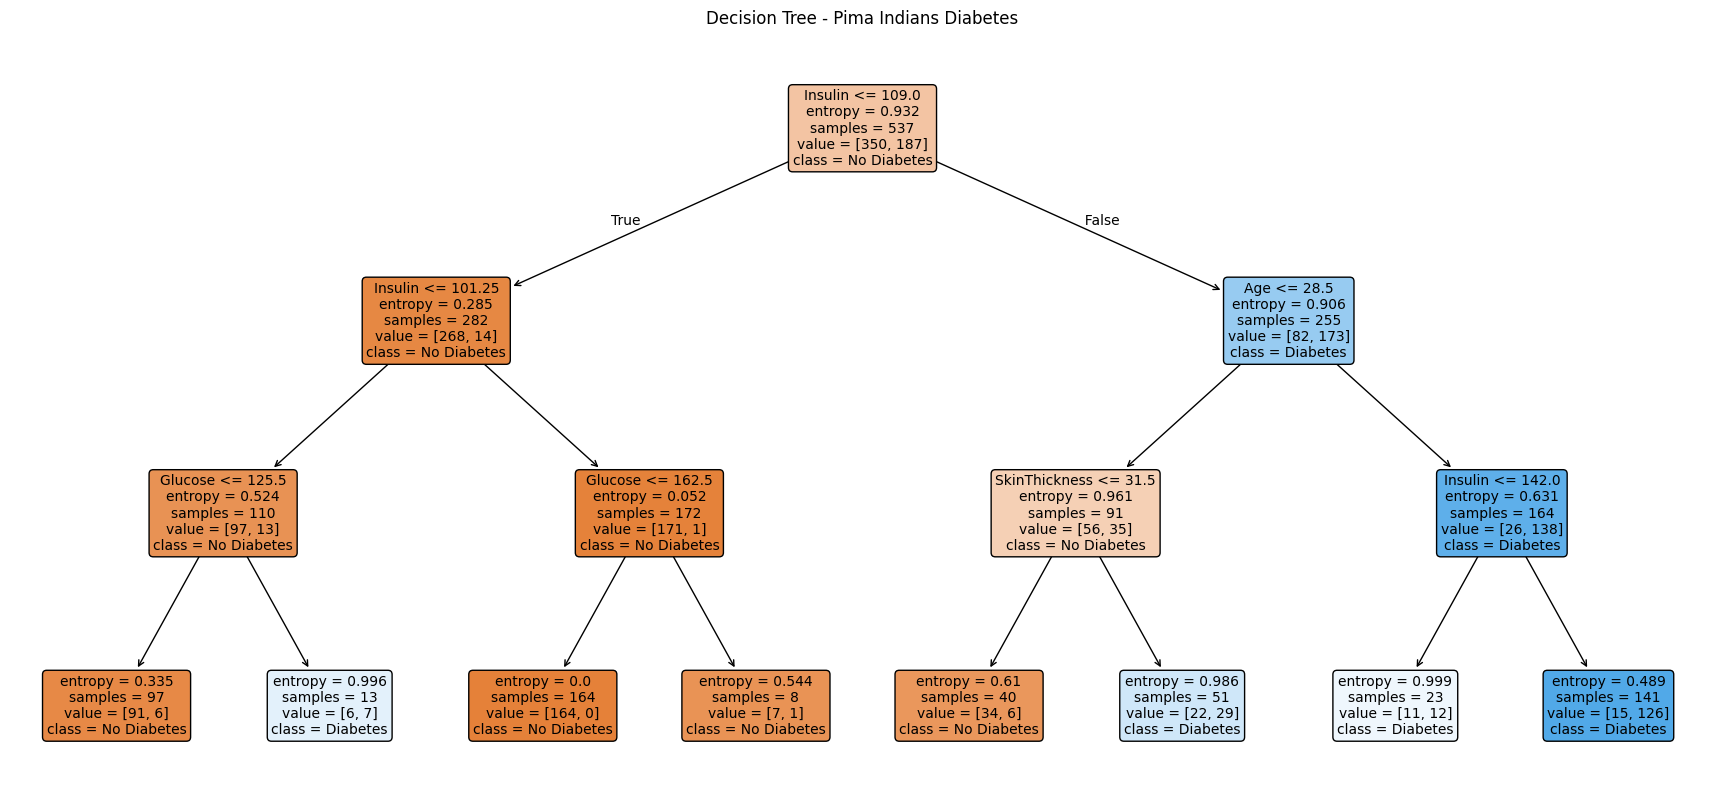

Conclusion: the top box (root) splits on 'Insulin'. Each box shows the rule, its entropy, number of samples, class counts and the majority class. Darker colour = purer node (more certain prediction).


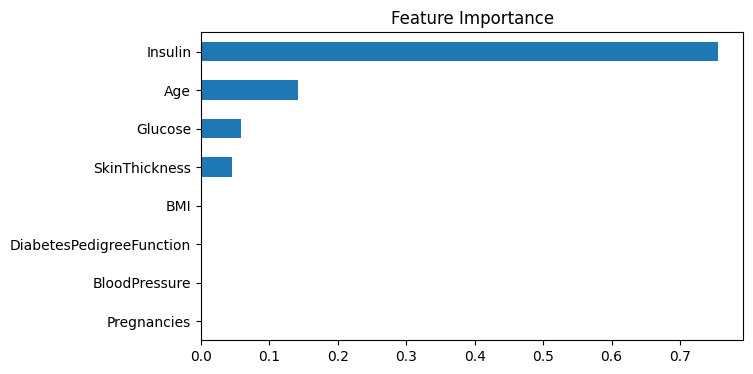

Conclusion: 'Insulin' is the most important feature in the tree (importance = 0.755), and it is also the root node, so the feature that makes the first and purest split also contributes the most overall.


In [ ]:
plt.figure(figsize=(22, 10))
plot_tree(clf, feature_names=feature_cols, class_names=['No Diabetes', 'Diabetes'],
          filled=True, rounded=True, fontsize=10)
plt.title("Decision Tree - Pima Indians Diabetes")
plt.show()

root_feature = feature_cols[clf.tree_.feature[0]]

print(f"Conclusion: the top box (root) splits on '{root_feature}'. Each box shows the rule, "
      "its entropy, number of samples, class counts and the majority class. "
      "Darker colour = purer node (more certain prediction).")

imp = pd.Series(clf.feature_importances_, index=feature_cols).sort_values()
imp.plot(kind='barh', figsize=(7, 4), title='Feature Importance')
plt.show()

top_feature = imp.index[-1]

if top_feature == root_feature:
    print(f"Conclusion: '{top_feature}' is the most important feature in the tree "
          f"(importance = {imp.iloc[-1]:.3f}), and it is also the root node, "
          "so the feature that makes the first and purest split also contributes the most overall.")
else:
    print(f"Conclusion: '{top_feature}' is the most important feature "
          f"(importance = {imp.iloc[-1]:.3f}), while the root node is '{root_feature}'. "
          "This is fine: importance adds up the impurity reduction from every split a feature "
          "makes, so a feature used several times lower down can outrank the root.")